In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

import matplotlib

from cycler import cycler

color=['0.0', '0.4', '0.8']
default_cycler = (cycler(color=color))
linestyle=['-', '--', ':', '-.']
marker=['o', 'v', 'd', 'p']

plt.rc('axes', prop_cycle=default_cycler)

matplotlib.rcParams.update({'font.size': 18})

In [2]:
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
apply_beamer_theme(
    "madrid",
    skip_font_download=True,
    author="Robert Pettis",
    date="Fall 2026",
    show_slide_number=True,
    cell_tags=True,
    notebook_path="16-Effect-Heterogeneity.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 12 cell(s):
 cell_index   slide_id                                  tags
         11  slide-3-0 slide_hide_prompt, slide_remove_input
         26 slide-11-1 slide_hide_prompt, slide_remove_input
         29 slide-12-0 slide_hide_prompt, slide_remove_input
         31 slide-12-1 slide_hide_prompt, slide_remove_input
         34 slide-13-1 slide_hide_prompt, slide_remove_input
         35 slide-13-1 slide_hide_prompt, slide_remove_input
         37 slide-14-0 slide_hide_prompt, slide_remove_input
         39 slide-14-1 slide_hide_prompt, slide_remove_input
         41 slide-15-0 slide_hide_prompt, slide_remove_input
         43 slide-16-0 slide_hide_prompt, slide_remove_input
         47 slide-16-3 slide_hide_prompt, slide_remove_input
         50 slide-17-0 slide_hide_prompt, slide_remove_input


In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Effect Heterogeneity

### Causal Machine Learning

<br>

<b style="color:#73000A;">Robert Pettis</b>
Fall 2026

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Propensity Score

- The <b style="color:#73000A;">propensity score</b> is $e(X) = P(T = 1 \mid X)$, many confounders reduced to one number
- Adjusting for $e(X)$ does the job of adjusting for all of $X$
- It needs <b style="color:#73000A;">overlap</b>: treated and untreated people at the same score
- That gives one average effect. Today asks <b style="color:#73000A;">who it works for</b>


### Where We Are Going

- Until now: <b style="color:#73000A;">does</b> the treatment work, on average
- Today: <b style="color:#73000A;">for whom</b> does it work, and by how much
- The catch: we still never observe an individual effect
- So most of the hour is about <b style="color:#73000A;">evaluating</b> a model we cannot score directly
- Payoff: turning effect estimates into decisions

## From ATE to CATE

- The <b style="color:#73000A;">average treatment effect</b> summarizes the effect across the population:
$$ATE = E\big[Y_1 - Y_0\big]$$

- The <b style="color:#73000A;">conditional average treatment effect</b> is the average effect for people with characteristics $X=x$:
$$\tau(x) = E\big[Y_1 - Y_0 \mid X=x\big]$$

- To recover the ATE, take each person's CATE and average across people:
$$ATE = E\big[\tau(X)\big] \approx \frac{1}{n}\sum_{i=1}^{n}\tau(X_i)$$

- For example, if 60% of people have a CATE of 10 and 40% have a CATE of 5:
$$ATE = 0.6(10) + 0.4(5) = 8$$


### What CATE is NOT

- What you want for customer $i$ is the <b style="color:#73000A;">individual treatment effect</b>, $\;Y_{1i} - Y_{0i}$
- You never see both potential outcomes for the same unit, so the ITE is <b style="color:#73000A;">unobservable</b>. 
- $\tau(x)$ is a <b style="color:#73000A;">group average</b>: the mean effect among units sharing covariates $x$
- Two customers with identical $x$ can still respond differently
   - $\tau(x)$ because it is the best <b style="color:#73000A;">identifiable</b> stand-in for the ITE

## The CATE You Are Familiar With

- Let the treatment's slope depend on the covariates by <b style="color:#73000A;">interacting</b> them:
$$y_i = \beta_0 + \beta_1 t_i + \boldsymbol{\beta}_2' \mathbf{x}_i + \boldsymbol{\beta}_3' \big(t_i \cdot \mathbf{x}_i\big) + e_i$$
- Differentiate with respect to the treatment and the CATE estimate falls out:
$$\widehat{\tau}(\mathbf{x}) = \frac{\partial \hat{y}}{\partial t} = \hat{\beta}_1 + \boldsymbol{\hat{\beta}}_3' \mathbf{x}$$


### Restaurant Example

In [4]:
data = pd.read_csv("./data/daily_restaurant_sales.csv")

data.head()

,rest_id,day,month,weekday,weekend,is_holiday,is_dec,is_nov,competitors_price,discounts,sales
0,0,2016-01-01,1,4,False,True,False,False,2.88,0,79.0
1,0,2016-01-02,1,5,True,False,False,False,2.64,0,57.0
2,0,2016-01-03,1,6,True,False,False,False,2.08,5,294.0
3,0,2016-01-04,1,0,False,False,False,False,3.37,15,676.5
4,0,2016-01-05,1,1,False,False,False,False,3.79,0,66.0


### The Model

- Let $Y_i$ be sales, $T_i$ the discount and $X_i$ contain month, weekday, holiday, and competitor price (using indicators for categorical variables).

$$
Y_i = \alpha + \beta^\top X_i + \theta T_i + T_i\,\gamma^\top X_i + \varepsilon_i
$$

- The interactions allow the effect of discount to vary with $X_i$:
$$
\tau(X_i) = \theta + \gamma^\top X_i
$$


- We could just get the parameters of $\tau(X_i) = \theta + \gamma^\top X_i$ from the fitted model...

- Or could simplify with definition of derivative where $\epsilon$ approaches zero:

$$
\dfrac{\partial y}{\partial t} = \dfrac{y(t+\epsilon) - y(t)}{(t+e) - t}
$$

- We can approximate this by replacing $\epsilon$ with 1:

$$
\dfrac{\partial y}{\partial t} = \hat{y}(t+1)-\hat{y}(t)
$$

In [5]:
import statsmodels.formula.api as smf

X = ["C(month)", "C(weekday)", "is_holiday", "competitors_price"]
regr_cate = smf.ols(f"sales ~ discounts*({'+'.join(X)})",
                    data=data).fit()

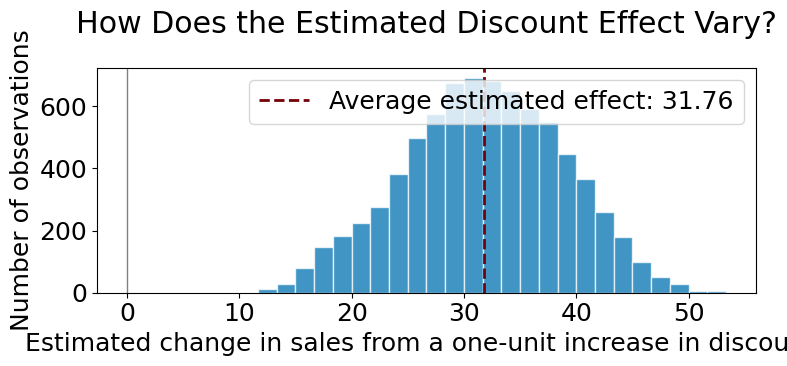

In [6]:
# Show how the estimated effect of a one-unit increase in discounts varies across observations.
ols_cate_pred = (
    regr_cate.predict(data.assign(discounts=data["discounts"] + 1))
    - regr_cate.predict(data)
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(ols_cate_pred, bins=25, color="#0072B2", alpha=0.75, edgecolor="white")
ax.axvline(
    ols_cate_pred.mean(), color="#73000A", linestyle="--", linewidth=2,
    label=f"Average estimated effect: {ols_cate_pred.mean():.2f}"
)
ax.axvline(0, color="gray", linewidth=1)

ax.set_xlabel("Estimated change in sales from a one-unit increase in discounts")
ax.set_ylabel("Number of observations")
ax.set_title("How Does the Estimated Discount Effect Vary?", pad=25)
ax.legend()

plt.tight_layout()
plt.show()

## Evaluating CATE Predictions

- Train on 2016-2017, test on 2018+
- Fit regression CATE on train, predict on test
- Three models:
  - Regression CATE (treatment interaction)
  - ML model (GradientBoosting on outcome, so pure prediction of Y)
  - Random baseline (so, a bad model...)

In [7]:
train = data.query("day<'2018-01-01'")
test = data.query("day>='2018-01-01'")

In [8]:
# OLS TRAINING ON TRAIN
X = ["C(month)", "C(weekday)", "is_holiday", "competitors_price"]
regr_model = smf.ols(f"sales ~ discounts*({'+'.join(X)})",
                     data=train).fit()

# PREDICTIONS ON TEST
cate_pred = (
    regr_model.predict(test.assign(discounts=test["discounts"]+1)) 
    -regr_model.predict(test)
)

In [9]:
# Gradient Boost
from sklearn.ensemble import GradientBoostingRegressor

X = ["month", "weekday", "is_holiday", "competitors_price", "discounts"]
y = "sales"

np.random.seed(1)
ml_model = GradientBoostingRegressor(n_estimators=50).fit(train[X],
                                                          train[y])

ml_pred = ml_model.predict(test[X])

In [10]:
# Store all 3 in test_pred
np.random.seed(123)

test_pred = test.assign(
    ml_pred=ml_pred,
    cate_pred=cate_pred,
    rand_m_pred=np.random.uniform(-1, 1, len(test)),
)

test_pred.head()

,rest_id,day,month,weekday,weekend,is_holiday,is_dec,is_nov,competitors_price,discounts,sales,ml_pred,cate_pred,rand_m_pred
731,0,2018-01-01,1,0,False,True,False,False,4.92,5,251.5,236.312960,41.355802,0.392938
732,0,2018-01-02,1,1,False,False,False,False,3.06,10,541.0,470.218050,44.743887,-0.427721
733,0,2018-01-03,1,2,False,False,False,False,4.61,10,431.0,429.180652,39.783798,-0.546297
734,0,2018-01-04,1,3,False,False,False,False,4.84,20,760.0,769.159322,40.770278,0.102630
735,0,2018-01-05,1,4,False,False,False,False,6.29,0,78.0,83.426070,40.666949,0.438938


### What Effect Are We Estimating In This Example?

- For a given month, weekday, holiday status, and competitor price:
  **How much would expected sales change if we increased the discount by one unit?**

- This is the CATE: the average effect for observations with those characteristics.

- Our model allows this effect to differ across those characteristics.

### Calculate the CATE at Each Observation's Characteristics

The CATE is the **average effect for everyone sharing a set of characteristics**, not an individual's effect.

Suppose a group of observations shares these characteristics:

- **Month:** June
- **Weekday:** Monday
- **Holiday:** No
- **Competitor price:** $20
- **Discount:** 2

Keep these characteristics fixed and increase the discount by one:

| Discount | Predicted sales |
|---|---:|
| 2 | 100 |
| 3 | 108 |

$$
\hat{\tau}(X_i)
=
\hat{Y}(3,X_i)-\hat{Y}(2,X_i)
=
108-100=8
$$

The estimated effect is **8 additional sales on average for June Mondays that are not holidays, when the competitor price is $20**.

Every observation with these same characteristics receives the same estimated CATE in this model.

## Scoring a CATE Model with the Cumulative Effect Curve

We cannot check one day's effect, but we can check a group's average effect by comparing days within it at different discounts.

1. **Predict:** Each model gives every test day a score. For the regression CATE, the score is the predicted effect of one more unit of discount:
$$
\hat{\tau}(X_i)
=
\hat{Y}(T_i+1,X_i)-\hat{Y}(T_i,X_i)
$$

2. **Rank:** Sort days from highest to lowest score.

3. **Grow:** Take the top $k$% of days and estimate their effect with a regression of sales on discounts:
$$
Y_i = \alpha_k + \tau_k T_i + \varepsilon_i,
\qquad i \in \text{top } k\%
$$
   - Top 1%: the first 26 of the 2,562 test days
   - Top 2%: the first 51, the same 26 plus the next 25
   - Top 3%: the first 77, and so on up to 100%

The estimated slope $\hat{\tau}_k$ is the height of the curve at $k$. 
- A good model starts high and slides down to the ATE.
- Bad model: flat or erratic

### The Model Ranks, the Data Measures

The model and the data have two separate jobs in this curve.

| | Comes from | Estimated on | Used for |
|---|---|---|---|
| Order of days (x axis) | The model's predicted effect | <b style="color:#73000A;">Training</b> days | Deciding who is in the top $k$% |
| Height of the curve (y axis) | Slope of sales on discounts in the group | <b style="color:#73000A;">Test</b> days the model never saw | Measuring the effect in that group |

- <b style="color:#73000A;">The model only ranks.</b> Its scores decide which days come first. After sorting, we never use the scores again
- <b style="color:#73000A;">The data measures.</b> For each top group, the height is the slope of actual sales on actual discounts for those days
- Both are slopes of sales on discounts. The model's slope comes from a formula fit on the training days. The height is a plain slope among the test days the model put first
- Why keep them apart? If the model's own predictions set the height, the model would be grading its own homework, and it would always look good. Measuring on the test days asks whether what it learned holds on new days
- A baseball version: a scout ranks 100 players by predicted batting average. To check the scout, we do not average the scout's predictions for the top 10. We look up the top 10's real batting averages
- So the curve asks one question: do the days the model put first <b style="color:#73000A;">really</b> respond more to discounts?

### Read the Distribution of Estimated Effects

- **Horizontal axis:** estimated change in sales from a one-unit increase in discount.
- **Vertical axis:** number of observations with an estimated effect in that range.
- **Dashed line:** the average estimated effect across all observations.

A wider distribution means the model estimates more variation in effects.

**These are model estimates:** their spread can reflect both real differences and estimation noise.

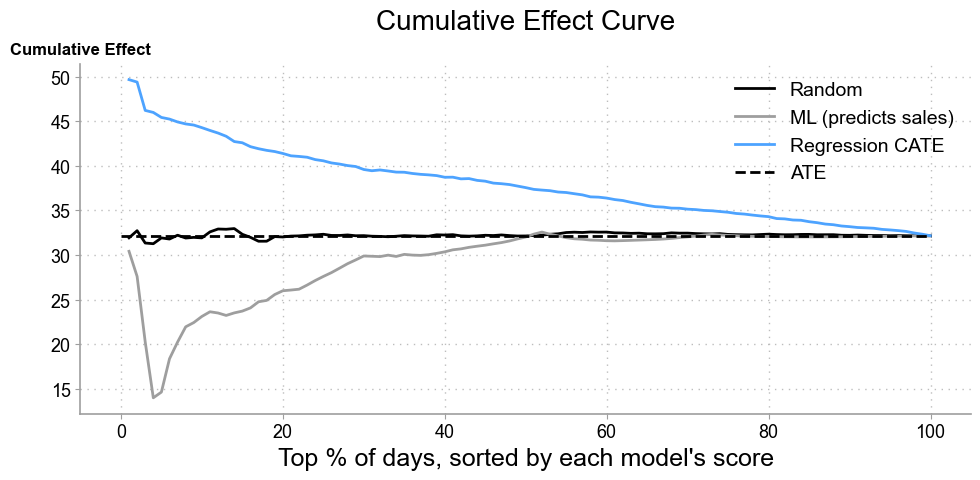

In [11]:
from toolz import curry

@curry
def effect(data, y, t):
    # slope of y on t: cov(t, y) / var(t)
    return (np.sum((data[t] - data[t].mean())*data[y]) /
            np.sum((data[t] - data[t].mean())**2))

def cumulative_effect_curve(dataset, prediction, y, t, ascending=False, steps=100):
    size = len(dataset)
    ordered_df = (dataset
                  .sort_values(prediction, ascending=ascending)
                  .reset_index(drop=True))
    steps_arr = np.linspace(size/steps, size, steps).round(0)
    return np.array([effect(ordered_df.query(f"index<={int(row)}"), t=t, y=y)
                     for row in steps_arr])

use_plotplainblind("scatter")
fig, ax = plt.subplots(figsize=(10, 5))
names = {"rand_m_pred": "Random", "ml_pred": "ML (predicts sales)", "cate_pred": "Regression CATE"}
for m in ["rand_m_pred", "ml_pred", "cate_pred"]:
    cumu_effect = cumulative_effect_curve(test_pred, m, "sales", "discounts", steps=100)
    x = np.arange(1, len(cumu_effect) + 1)   # point k is the top k%
    ax.plot(x, cumu_effect, marker="", linewidth=2, label=names[m])

ate = effect(test_pred, "sales", "discounts")
ax.hlines(ate, 0, 100, linestyles="--", color="black", linewidth=2, label="ATE")
ax.set_xlabel("Top % of days, sorted by each model's score")
set_top_ylabel(ax, "Cumulative Effect", fontsize=12, fontweight="bold")
ax.set_title("Cumulative Effect Curve", pad=25)
ax.legend()
plt.tight_layout()

### Reading the Curve

- <b style="color:#73000A;">x axis</b>: how far down the model's ranking we go. At 10%, we keep the 10% of days with the highest scores
- <b style="color:#73000A;">y axis</b>: the effect estimated from the data among those days. No prediction goes into it
- <b style="color:#73000A;">Regression CATE</b>: about 49 extra sales per unit of discount in its top 1%, 44 in its top 10%, 38 in its top half, then down to the ATE of 32. It ranks well
- <b style="color:#73000A;">Random</b>: flat at 32 the whole way. It cannot rank
- <b style="color:#73000A;">ML</b>: <i>below</i> the ATE at the top, about 14 in its top 5%. The days it expects to sell the most respond less than average to discounts
- The first few percent are a small sample, so do not read much into the left edge

## Cumulative Gain Curve

- Scale effect by fraction of units treated
- Gain = effect * $N_{cum}/N$
- Area under curve summarizes model quality
- Now the beginning of the curve will have the highest effect but will be scaled back by the lack of sample size
- You can also normalize the curve by the ATE

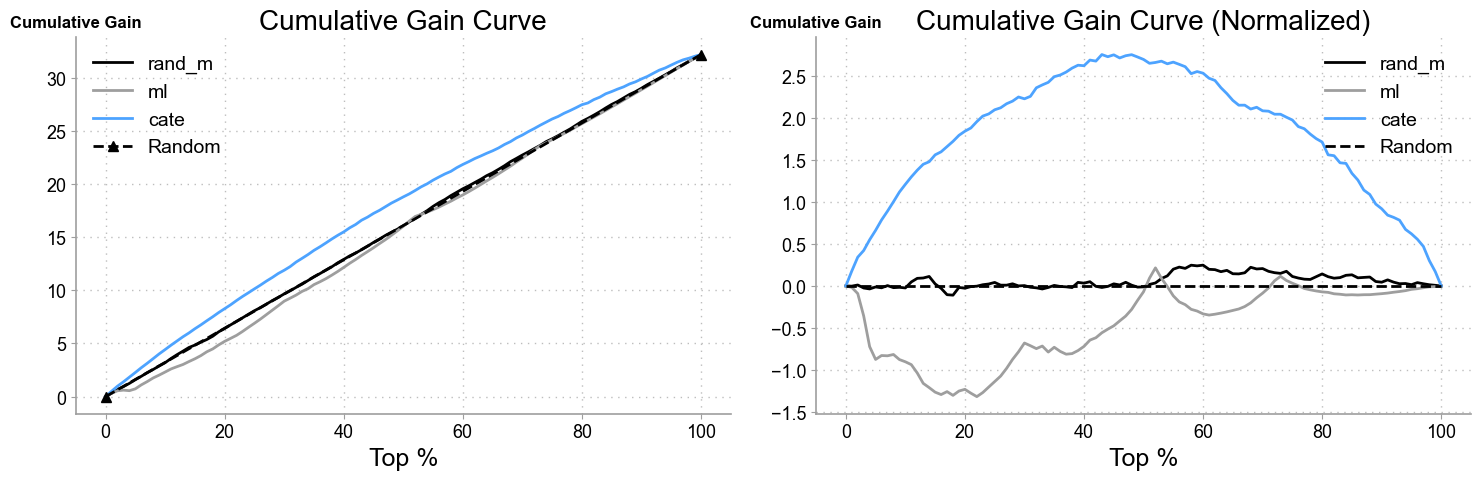

In [12]:
def cumulative_gain_curve(df, prediction, y, t, ascending=False, normalize=False, steps=100):
    effect_fn = effect(t=t, y=y)
    normalizer = effect_fn(df) if normalize else 0
    size = len(df)
    ordered_df = (df
                  .sort_values(prediction, ascending=ascending)
                  .reset_index(drop=True))
    steps_arr = np.linspace(size/steps, size, steps).round(0)
    effects = [(effect_fn(ordered_df.query(f"index<={int(row)}"))
                -normalizer)*(row/size)
               for row in steps_arr]
    return np.array([0] + effects)

use_plotplainblind("scatter")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for m in ["rand_m_pred", "ml_pred", "cate_pred"]:
    cumu_gain = cumulative_gain_curve(test_pred, m, "sales", "discounts", steps=100)
    x = np.array(range(len(cumu_gain)))
    ax1.plot(100*(x/x.max()), cumu_gain, marker="", linewidth=2, label=m.replace("_pred", ""))

ate = effect(test_pred, "sales", "discounts")
ax1.plot([0, 100], [0, ate], linestyle="--", color="black", linewidth=2, label="Random")
ax1.set_xlabel("Top %")
set_top_ylabel(ax1, "Cumulative Gain", fontsize=12, fontweight="bold")
ax1.set_title("Cumulative Gain Curve")
ax1.legend()

for m in ["rand_m_pred", "ml_pred", "cate_pred"]:
    cumu_gain_norm = cumulative_gain_curve(test_pred, m, "sales", "discounts", normalize=True, steps=100)
    x = np.array(range(len(cumu_gain_norm)))
    ax2.plot(100*(x/x.max()), cumu_gain_norm, marker="", linewidth=2, label=m.replace("_pred", ""))

ax2.hlines(0, 0, 100, linestyle="--", color="black", linewidth=2, label="Random")
ax2.set_xlabel("Top %")
set_top_ylabel(ax2, "Cumulative Gain", fontsize=12, fontweight="bold")
ax2.set_title("Cumulative Gain Curve (Normalized)")
ax2.legend()
plt.tight_layout()

### Model Performance With One Number

- To compare models with a single number, <b style="color:#73000A;">add up the values of the normalized gain curve</b> (the right panel)
- That sum is the area under the curve, the <b style="color:#73000A;">AUC</b>. The bigger it is, the better the model orders the CATE
- Random lands near 0, as it should: its curve hugs the flat line
- A <b style="color:#73000A;">negative</b> area means the model does worse than random at ordering the effect
- Regression CATE has by far the largest area

### Keep In Mind...

- Each number is an ESTIMATE
- The curves tell us if our ordering is correct, not if our model is correctly specified
- We still need unconfoundedness

In [13]:
names = {"rand_m_pred": "Random", "ml_pred": "ML (predicts sales)", "cate_pred": "Regression CATE"}
for m in ["rand_m_pred", "ml_pred", "cate_pred"]:
    gain = cumulative_gain_curve(test_pred, m, "sales", "discounts", normalize=True)
    print(f"AUC for {names[m]:<20} {sum(gain):8.2f}")

AUC for Random                   6.07
AUC for ML (predicts sales)    -45.47
AUC for Regression CATE        181.74


## Target Transformation

- Build a <b style="color:#73000A;">pseudo outcome</b> whose conditional mean is the CATE itself:
$$Y^*_i = Y_i \cdot \frac{T_i - e(x_i)}{e(x_i)\,\big(1 - e(x_i)\big)}$$
- Once treatment is unconfounded given $x$, taking expectations term by term gives
$$E\big[\,Y^* \mid X = x\,\big] = \tau(x)$$
- So any regression of $Y^*$ on $X$ is a CATE model, and any prediction metric on $Y^*$ scores it
- With randomization, $e(x) = p$ is a constant and the weights are just $1/p$ and $-1/(1-p)$
- The price: $Y^*$ is <b style="color:#73000A;">noisy</b>, one unit's pseudo outcome is nearly meaningless; only averages over regions of $x$ carry signal

## When Prediction Helps Effect Ordering

- Prediction models are good at ordering CATE when outcome [$y$] and effect [$\tau(x_i)$] correlate
    - If custmers are more responsive to discounts on days when sales are high: a model that predicts $y$ will be good at ordering the effect of $T$ on $y$
- Happens with <b style="color:#73000A;">nonlinear</b> treatment response
  - Marginal decreasing returns (concave)
  - Binary outcomes (S-shaped, logistic)
- In these cases, high-Y units also have high slopes

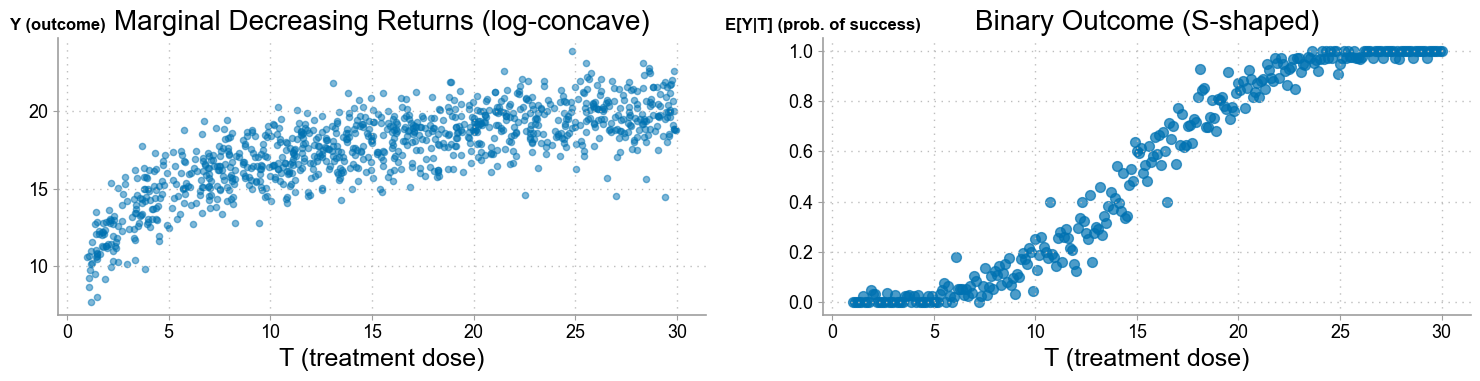

In [16]:
use_plotplainblind("scatter")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

np.random.seed(123)
n = 1000
t = np.random.uniform(1, 30, size=n)
y = np.random.normal(10 + 3*np.log(t), 1.5, size=n)

ax = axes[0]
ax.scatter(t, y, color="#0072B2", alpha=0.5, s=20)
ax.set_xlabel("T (treatment dose)")
set_top_ylabel(ax, "Y (outcome)", fontsize=12, fontweight="bold")
ax.set_title("Marginal Decreasing Returns (log-concave)")

np.random.seed(123)
n = 10000
t_bin = np.random.uniform(1, 30, size=n).round(1)
y_bin = (np.random.normal(t_bin, 5, size=n) > 15).astype(int)
df_bin = pd.DataFrame({"t": t_bin, "y": y_bin}).groupby("t")["y"].mean().reset_index()

ax = axes[1]
ax.scatter(df_bin["t"], df_bin["y"], color="#0072B2", alpha=0.7, s=50)
ax.set_xlabel("T (treatment dose)")
set_top_ylabel(ax, "E[Y|T] (prob. of success)", fontsize=12, fontweight="bold")
ax.set_title("Binary Outcome (S-shaped)")
plt.tight_layout()

### Outcome versus Effect: When Ranking Disagrees

Highest outcome does NOT always mean highest effect.
Units with high Y might be high because of other factors, not treatment response.

In [17]:
# Create a numeric example where Y rank and tau rank differ
np.random.seed(789)
n_demo2 = 8

demo2_df = pd.DataFrame({
    'unit': np.arange(1, n_demo2 + 1),
    'treatment': np.array([1, 0, 1, 0, 1, 0, 1, 0]),
    'outcome': np.array([95, 92, 45, 42, 88, 85, 52, 50])
})

# Compute effect: diff in means for treated vs control within each unit's perceived group
# Create pseudo-units by pairing treated/control
pairs_effect = []
pairs_outcome = []
for i in range(0, n_demo2, 2):
    treated_y = demo2_df.iloc[i]['outcome']
    control_y = demo2_df.iloc[i+1]['outcome']
    effect = treated_y - control_y
    avg_outcome = (treated_y + control_y) / 2
    pairs_effect.append(effect)
    pairs_outcome.append(avg_outcome)

demo2_df['pair'] = demo2_df.index // 2 + 1
demo2_df['pair_effect'] = demo2_df['pair'].map(lambda x: pairs_effect[x-1])
demo2_df['pair_outcome'] = demo2_df['pair'].map(lambda x: pairs_outcome[x-1])

print("Eight units organized in treated/control pairs:")
print(demo2_df[['unit', 'pair', 'treatment', 'outcome', 'pair_effect']].to_string(index=False))
print()

# Rank by outcome
demo_ranked_outcome = demo2_df.drop_duplicates('pair').sort_values('pair_outcome', ascending=False)
print("Rank by OUTCOME (high to low):")
print(demo_ranked_outcome[['pair', 'pair_outcome', 'pair_effect']].to_string(index=False))
print()

# Rank by effect
demo_ranked_effect = demo2_df.drop_duplicates('pair').sort_values('pair_effect', ascending=False)
print("Rank by EFFECT (high to low):")
print(demo_ranked_effect[['pair', 'pair_effect', 'pair_outcome']].to_string(index=False))
print()

print("DISAGREEMENT: Pair 1 has the highest outcome (93.5) but NOT the highest effect (3).")
print("Pair 4 has lower outcome (51) but highest effect (2).")

Eight units organized in treated/control pairs:
 unit  pair  treatment  outcome  pair_effect
    1     1          1       95            3
    2     1          0       92            3
    3     2          1       45            3
    4     2          0       42            3
    5     3          1       88            3
    6     3          0       85            3
    7     4          1       52            2
    8     4          0       50            2

Rank by OUTCOME (high to low):
 pair  pair_outcome  pair_effect
    1          93.5            3
    3          86.5            3
    4          51.0            2
    2          43.5            3

Rank by EFFECT (high to low):
 pair  pair_effect  pair_outcome
    1            3          93.5
    2            3          43.5
    3            3          86.5
    4            2          51.0

DISAGREEMENT: Pair 1 has the highest outcome (93.5) but NOT the highest effect (3).
Pair 4 has lower outcome (51) but highest effect (2).


## Binary Outcomes: The Curve Sets the Effect

- With a binary outcome, the response is an <b style="color:#73000A;">S-curve</b>: $P(Y=1)$ against the index
- The same nudge to the index moves probability <b style="color:#73000A;">most in the middle</b> and barely at the flat ends
- A customer already at 95% conversion has almost no room to move; one at 50% has the most
- So once the outcome is binary, the <b style="color:#73000A;">baseline probability itself</b> carries effect information, and outcome ordering becomes a sensible starting guess for effect ordering

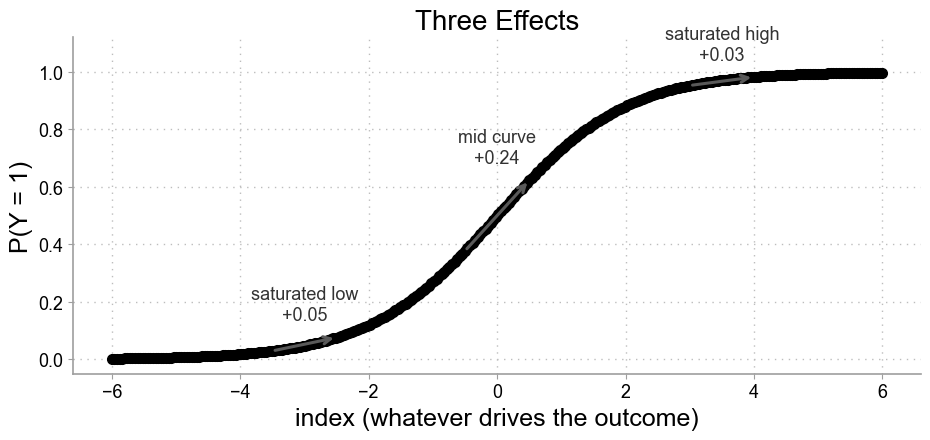

In [18]:
from scipy.special import expit

idx = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(idx, expit(idx), color="0.0", lw=2.5)
for x0, name in [(-3.5, "saturated low"), (-0.5, "mid curve"),
                 (3.0, "saturated high")]:
    p0, p1 = expit(x0), expit(x0 + 1.0)
    ax.annotate("", xy=(x0 + 1.0, p1), xytext=(x0, p0),
                arrowprops=dict(arrowstyle="->", lw=2.2, color="0.35"))
    ax.text(x0 + 0.5, p1 + 0.06, f"{name}\n+{p1 - p0:.2f}",
            ha="center", fontsize=13, color="0.2")
ax.set_xlabel("index (whatever drives the outcome)")
ax.set_ylabel("P(Y = 1)")
ax.set_ylim(-0.05, 1.12)
ax.set_title("Three Effects")
plt.tight_layout()
plt.show()

## CATE for Decision Making

- Binary treatment: if CATE > 0, treat that unit if money is no object
   - If money is an issue, then use cumulative plot (or a non-cumulative version) to determine cut-off you can live with
- Continuous treatment: harder
   - Not only who to treat, but how much
   - How to handle is business specific


optimize $T_i^* = \arg\max_t Profit_i(T_i)$
- Model revenue and cost as functions of treatment
- Use estimated CATE to solve for optimal treatment

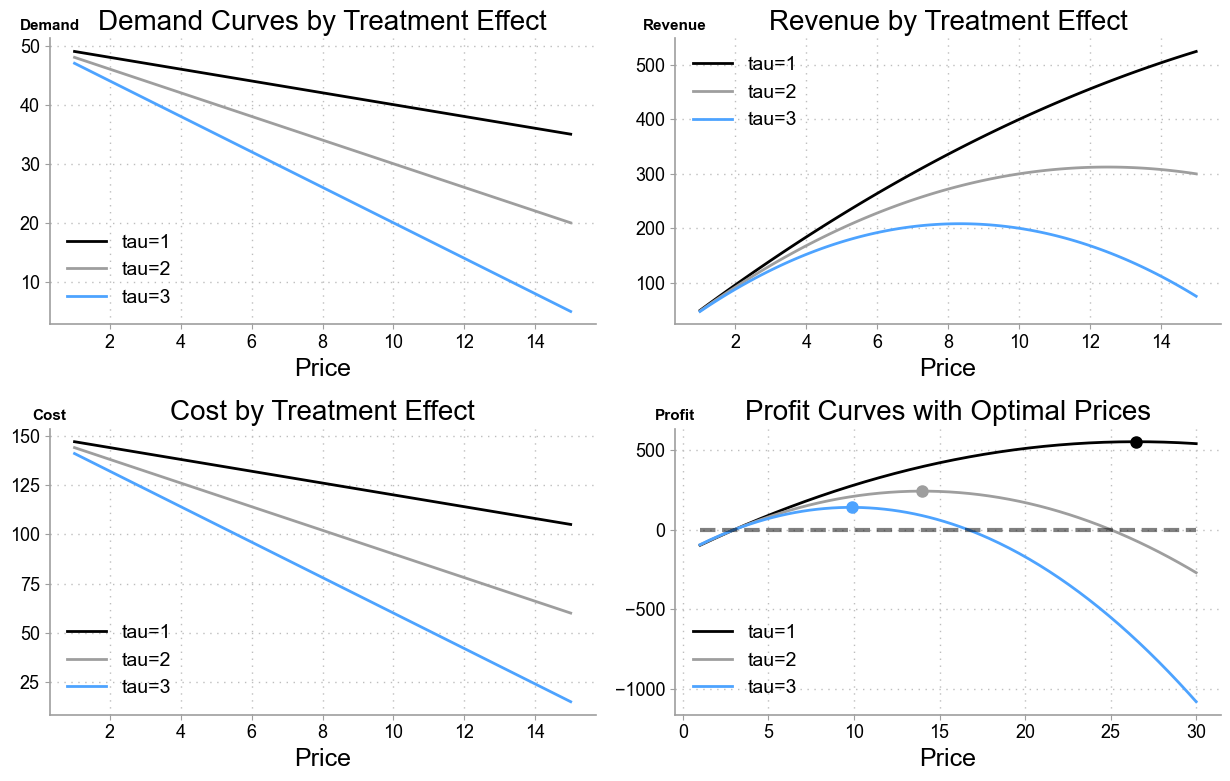

In [19]:
use_plotplainblind("scatter")

def demand(price, tau):
    return 50 - tau*price

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
prices = np.linspace(1, 15, 100)

ax = axes[0, 0]
for i, tau in enumerate([1, 2, 3]):
    q = demand(prices, tau)
    ax.plot(prices, q, marker="", linewidth=2, label=f"tau={tau}")
set_top_ylabel(ax, "Demand", fontsize=11, fontweight="bold")
ax.set_xlabel("Price")
ax.set_title("Demand Curves by Treatment Effect")
ax.legend()

ax = axes[0, 1]
for i, tau in enumerate([1, 2, 3]):
    q = demand(prices, tau)
    ax.plot(prices, q*prices, marker="", linewidth=2, label=f"tau={tau}")
set_top_ylabel(ax, "Revenue", fontsize=11, fontweight="bold")
ax.set_xlabel("Price")
ax.set_title("Revenue by Treatment Effect")
ax.legend()

def cost(q):
    return q * 3

ax = axes[1, 0]
for i, tau in enumerate([1, 2, 3]):
    q = demand(prices, tau)
    ax.plot(prices, cost(q), marker="", linewidth=2, label=f"tau={tau}")
set_top_ylabel(ax, "Cost", fontsize=11, fontweight="bold")
ax.set_xlabel("Price")
ax.set_title("Cost by Treatment Effect")
ax.legend()

def profit(price, tau):
    q = demand(price, tau)
    return q*price - cost(q)

ax = axes[1, 1]
prices_fine = np.linspace(1, 30, 200)
for i, tau in enumerate([1, 2, 3]):
    profits = np.array([profit(p, tau) for p in prices_fine])
    max_idx = np.argmax(profits)
    max_price = prices_fine[max_idx]
    max_profit = profits[max_idx]
    ax.plot(prices_fine, profits, marker="", linewidth=2, label=f"tau={tau}")
    ax.plot(max_price, max_profit, marker="o", markersize=8, color=f"C{i}")
ax.hlines(0, prices_fine.min(), prices_fine.max(), color="black", linestyles="--", alpha=0.5)
set_top_ylabel(ax, "Profit", fontsize=11, fontweight="bold")
ax.set_xlabel("Price")
ax.set_title("Profit Curves with Optimal Prices")
ax.legend()
plt.tight_layout()

### Application: Personalized Prices

- The restaurant model estimates a <b style="color:#73000A;">price sensitivity per day type</b>; a seller with segments can estimate one per <b style="color:#73000A;">customer type</b>
- Ordering segments by estimated sensitivity licenses <b style="color:#73000A;">differential pricing</b>: discount where demand bends, hold price where it does not
- The cumulative gain curve is the business case: it reads off how much a personalized policy beats the one-price policy at each coverage level
- Constraints bind before statistics does: fairness, law, and arbitrage all limit how far prices can split

### Application: Scarce Doses

- A supply constraint turns CATE into a <b style="color:#73000A;">triage rule</b>: with $k$ doses, treat the $k$ largest estimated effects
- Ranking by <b style="color:#73000A;">risk</b> (the outcome level) is not the same as ranking by <b style="color:#73000A;">effect</b>; the highest risk patients are not always the most helped
- This is the outcome-versus-effect ordering distinction from earlier, now with lives attached
- The effect-by-quantile curve is the audit: it shows whether the priority groups actually benefited more

### Worked Decision Rule: Treat Top K Under Budget

Rank units by estimated effect. Budget allows k units to be treated.
Compute cumulative profit as you move down the ranking.

In [20]:
# Small example: 10 restaurants, budget to treat 4
np.random.seed(42)
n_rest = 10
budget_k = 4

rest_demo = pd.DataFrame({
    'restaurant': np.arange(1, n_rest + 1),
    'tau_pred': np.sort(np.random.uniform(0.5, 3.0, n_rest))[::-1],  # Descending
    'cost_per_discount': 2.0,  # Cost of giving discount to a restaurant
    'baseline_profit': np.array([50, 48, 55, 52, 45, 60, 42, 58, 46, 51])
})

# Assume applying treatment (discount) increases profit by tau_pred * 100
rest_demo['profit_with_discount'] = rest_demo['baseline_profit'] + rest_demo['tau_pred'] * 100
rest_demo['net_profit_gain'] = (rest_demo['profit_with_discount'] -
                                rest_demo['baseline_profit'] -
                                rest_demo['cost_per_discount'])
rest_demo['cumulative_gain'] = rest_demo['net_profit_gain'].cumsum()

print("Rank by predicted effect, compute marginal and cumulative profit:")
print(rest_demo[['restaurant', 'tau_pred', 'net_profit_gain', 'cumulative_gain']].to_string(index=False))
print()
print(f"Policy: Treat top {budget_k} restaurants")
print(f"Restaurants to treat: {list(rest_demo.head(budget_k)['restaurant'])}")
print(f"Total profit gain from treating top {budget_k}: {rest_demo.head(budget_k)['net_profit_gain'].sum():.1f}")

Rank by predicted effect, compute marginal and cumulative profit:
 restaurant  tau_pred  net_profit_gain  cumulative_gain
          1  2.876786       285.678577       285.678577
          2  2.665440       264.544036       550.222613
          3  2.329985       230.998485       781.221098
          4  2.270181       225.018144      1006.239243
          5  2.002788       198.278753      1204.517996
          6  1.996646       197.664621      1402.182617
          7  1.436350       141.635030      1543.817647
          8  0.890047        87.004660      1630.822307
          9  0.889986        86.998630      1717.820937
         10  0.645209        62.520903      1780.341840

Policy: Treat top 4 restaurants
Restaurants to treat: [1, 2, 3, 4]
Total profit gain from treating top 4: 1006.2


### Quantile Regression: Alternative Econometric View

Where linear regression estimates the mean treatment effect E[Y|T,X],
quantile regression estimates the effect at the median, quartiles, or any quantile.

Useful when treatment effects are not uniform across the distribution of Y.

## Key Ideas

- Treatment effects are <b style="color:#73000A;">heterogeneous</b>
- CATE: conditional average treatment effect on groups
- Estimate via regression: $Y = \beta_0 + \beta_1 T + \beta_3 X + \beta_4 T \times X$
- Slope prediction: $\hat{\tau}(x) = \beta_1 + \beta_4 x$
- Evaluate with effect-by-quantile and cumulative gain curves
- Use CATE for personalized treatment allocation

In [21]:
from statsmodels.regression.quantile_regression import QuantReg

# Fit quantile regression at tau=0.5 (median), 0.25, 0.75
X_qr = train[['month', 'weekday', 'is_holiday', 'competitors_price']].copy()
X_qr['const'] = 1.0

# Add treatment
X_qr_full = X_qr.copy()
X_qr_full['discounts'] = train['discounts'].values
y_train = train['sales'].values

taus = [0.25, 0.5, 0.75]
qr_effects = {}

for tau in taus:
    qr_model = QuantReg(y_train.astype(float),
                    X_qr_full[['const', 'discounts', 'month', 'weekday',
                               'is_holiday', 'competitors_price']]
                    .astype(float)).fit(q=tau)
    coef_discount = qr_model.params['discounts']
    qr_effects[tau] = coef_discount

print("Quantile Regression: Effect of Discount across the Distribution")
print()
for tau in sorted(taus):
    print(f"Tau={tau} (effect at {100*tau:.0f}-th quantile): {qr_effects[tau]:.2f}")
print()
print("Interpretation: The treatment effect on LOW-sales days (low quantile) differs")
print("from the effect on HIGH-sales days (high quantile).")
print("This is heterogeneity along the outcome distribution, not predictor space.")

Quantile Regression: Effect of Discount across the Distribution

Tau=0.25 (effect at 25-th quantile): 27.23
Tau=0.5 (effect at 50-th quantile): 31.35
Tau=0.75 (effect at 75-th quantile): 35.67

Interpretation: The treatment effect on LOW-sales days (low quantile) differs
from the effect on HIGH-sales days (high quantile).
This is heterogeneity along the outcome distribution, not predictor space.
